In [67]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fmin_l_bfgs_b
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import DotProduct, Matern, RBF, ConstantKernel

DOMAIN = np.array([[0, 10]])
SAFETY_THRESHOLD = 4

class My_Algo():
    def __init__(self):
        """Initializes the algorithm with a parameter configuration."""        
        objective_kernel = Matern(length_scale=0.225, nu=2.5)
        self.objective_model = GaussianProcessRegressor(kernel=objective_kernel)
        
        constraint_kernel = ConstantKernel(4) + (Matern(length_scale=0.225, nu=2.5))
        self.constraint_model = GaussianProcessRegressor(kernel=constraint_kernel)
        
        self.x = []
        self.yf = []
        self.yv = []
        
        self.init_point_unpacked = False

    def next_recommendation(self):
        return self.optimize_acquisition_function()

    def optimize_acquisition_function(self):
        def objective(x):
            return -self.acquisition_function(x)

        f_values = []
        x_values = []

        # Restarts the optimization 20 times and pick best solution
        for _ in range(20):
            x0 = DOMAIN[:, 0] + (DOMAIN[:, 1] - DOMAIN[:, 0]) * \
                 np.random.rand(DOMAIN.shape[0])
            result = fmin_l_bfgs_b(objective, x0=x0, bounds=DOMAIN,
                                   approx_grad=True)
            x_values.append(np.clip(result[0], *DOMAIN[0]))
            f_values.append(-result[1])

        ind = np.argmax(f_values)
        x_opt = x_values[ind].item()

        return x_opt

    def acquisition_function(self, x: np.ndarray):
        x = np.atleast_2d(x)
        mean,std=self.objective_model.predict(x,return_std=True)
        mean_constraint,std_constraint=self.constraint_model.predict(x,return_std=True)
        return mean + 10*std - 10*max(mean_constraint+0.225*std_constraint, 0)

    def add_data_point(self, x: float, f: float, v: float):      
        self.x.append(x)
        self.yf.append(f)
        self.yv.append(v)
        
        if not self.init_point_unpacked:
            self.x[0] = self.x[0][0]
            self.init_point_unpacked = True
        
        self.objective_model.fit(np.array(self.x).reshape(-1, 1), np.array(self.yf))
        self.constraint_model.fit(np.array(self.x).reshape(-1, 1), np.array(self.yv))

    def get_solution(self):
        def objective(x):
            x = np.atleast_2d(x)
            return -(self.objective_model.predict(x) - 10*max(self.constraint_model.predict(x), 0))

        f_values = []
        x_values = []

        # Restarts the optimization 20 times and pick best solution
        for _ in range(20):
            x0 = DOMAIN[:, 0] + (DOMAIN[:, 1] - DOMAIN[:, 0]) * \
                 np.random.rand(DOMAIN.shape[0])
            result = fmin_l_bfgs_b(objective, x0=x0, bounds=DOMAIN,
                                   approx_grad=True)
            x_values.append(np.clip(result[0], *DOMAIN[0]))
            f_values.append(-result[1])

        ind = np.argmax(f_values)
        x_opt = x_values[ind].item()

        return x_opt

    def plot(self, plot_recommendation: bool = True):
        print("Plotting...")
         
        X = np.linspace(start=0, stop=10, num=1000).reshape(-1, 1)
        mean_obj, std_obj = self.objective_model.predict(X, return_std=True)
        mean_con, std_con = self.constraint_model.predict(X, return_std=True)

        plt.subplot(2, 2, 1)
        plt.scatter(self.x, self.yf)
        plt.plot(X, mean_obj)
        plt.fill_between(
            X.ravel(),
            mean_obj - 1.96 * std_obj,
            mean_obj + 1.96 * std_obj,
            alpha=0.5,
        )
        plt.xlabel("$x$")
        plt.ylabel("$f(x)$")
        plt.xlim(0, 10)
        plt.ylim(-2, 5)
        plt.title("Objective Model")
        
        plt.subplot(2, 2, 2)
        plt.scatter(self.x, self.yv)
        plt.plot(X, mean_con)
        plt.fill_between(
            X.ravel(),
            mean_con - 1.96 * std_con,
            mean_con + 1.96 * std_con,
            alpha=0.5,
        )
        plt.xlabel("$x$")
        plt.ylabel("$v(x)$")
        plt.xlim(0, 10)
        plt.ylim(-2, 5)
        plt.title("Constraint Model")
        
        plt.show()

Plotting...


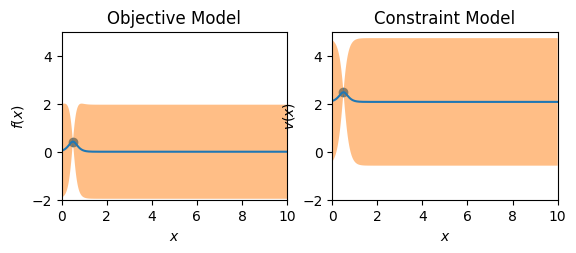

Next recommendation: 5.684529942975867
Plotting...


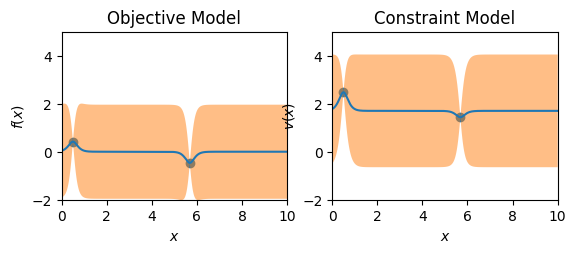

Next recommendation: 5.375284341148991
Plotting...


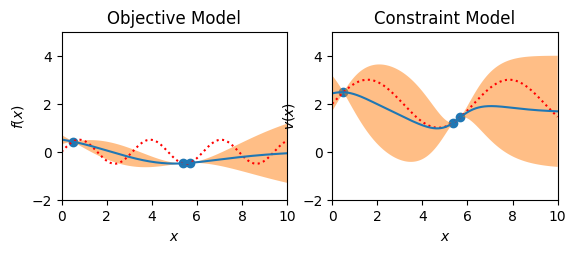

Next recommendation: 4.7120481853522325
Plotting...


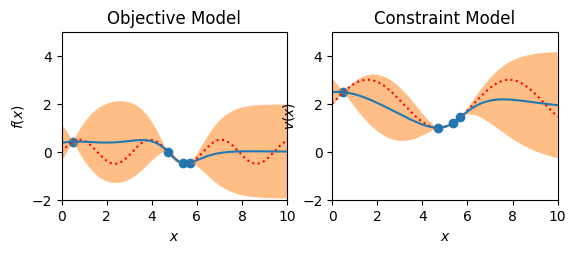

Next recommendation: 3.696244197505946
Plotting...


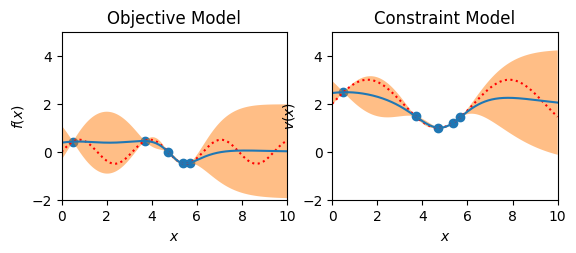

Next recommendation: 4.482176798706008
Plotting...


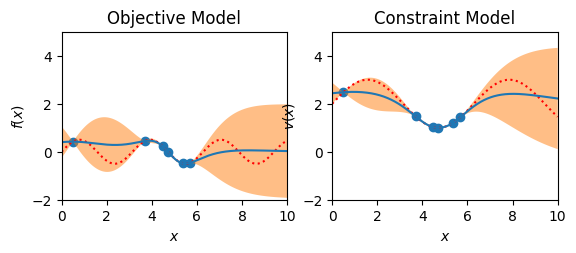

Next recommendation: 4.604799778065303
Plotting...


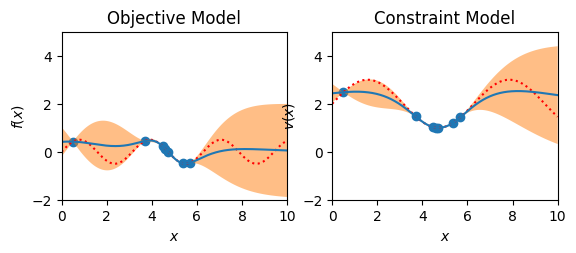

Next recommendation: 4.624968364620009
Plotting...


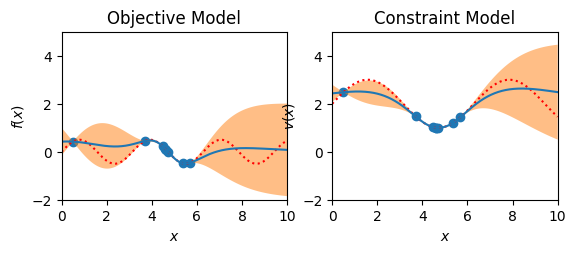

Next recommendation: 4.614245803640397


/home/albin/miniconda3/envs/pai-proj3/lib/python3.8/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


Plotting...


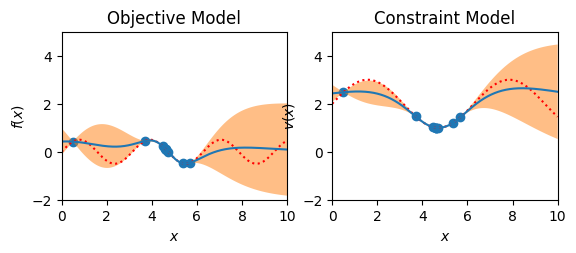

Next recommendation: 4.614195355905002
Plotting...


/home/albin/miniconda3/envs/pai-proj3/lib/python3.8/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/home/albin/miniconda3/envs/pai-proj3/lib/python3.8/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


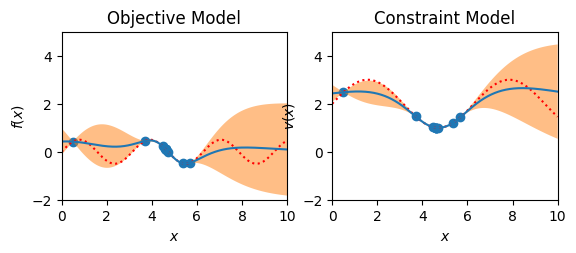

Next recommendation: 4.614182629814605
Plotting...


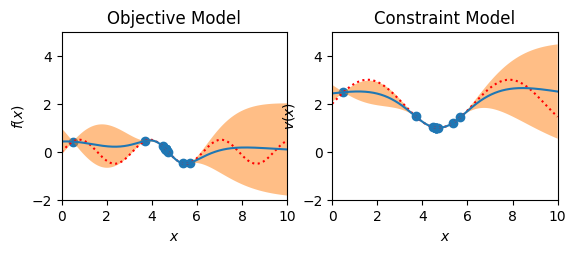

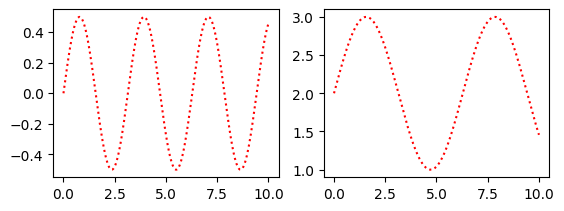

In [69]:
def f(x):
    return np.cos(x)*np.sin(x)

def v(x):
    return np.sin(x) + 2

agent = My_Algo()

agent.add_data_point([np.array(0.5)], f(0.5), v(0.5))
agent.plot()

for _ in range(10):
    x = agent.next_recommendation()
    print("Next recommendation:", x)
    obj_val = f(x)
    cost_val = v(x)
    agent.add_data_point(x, obj_val, cost_val)
    agent.plot()
    
    X = np.linspace(start=0, stop=10, num=1000).reshape(-1, 1)
    plt.subplot(2, 2, 1)
    plt.plot(X, f(X), linestyle='dotted', color='red')
    plt.subplot(2, 2, 2)
    plt.plot(X, v(X), linestyle='dotted', color='red')